# M6 · Fisher merging baseline and LOGO comparison

**M5 leave-one-generator-out** (video AUC %, held-out generator; pooled = λ = ∞, GBLA = λ = 0.01):

| held out | pooled | GBLA | gain |
|---|---|---|---|
| NeuralTextures | 64.40 | 62.29 | −2.11 |
| FaceSwap | 97.90 | 98.37 | +0.47 |
| Deepfakes | 99.21 | 99.22 | +0.01 |
| Face2Face | 85.40 | 87.40 | +2.00 |
| FaceShifter | 90.53 | 92.91 | +2.38 |
| **MEAN** | **87.49** | **88.04** | **+0.55** |

GBLA helps on FaceShifter and Face2Face, is flat on Deepfakes and FaceSwap (already near ceiling), and **hurts when NeuralTextures is held out**. The FaceShifter win from M4 is real but not uniform. Seen-generator AUC stays essentially the same (95.39 → 95.36).

**M6.** Compare three ways to combine the per-generator LN-tuning solutions:

1. **Pooled ERM** (λ = ∞ from M4/M5): train one model on all generators in the fold.
2. **GBLA** (λ = 0.01 from M4/M5): shared θ_s with private offsets, deploy θ_s.
3. **Fisher merge**: train one model per generator (M3 already has DF, F2F, FS, NT; M6 adds FaceShifter), then merge their LayerNorms and head by the diagonal empirical Fisher (sum of squared gradients on that generator's data). Uniform average of the four (or five) solutions is reported as a control.

No new long multi-epoch GBLA training. New work: one single-generator FaceShifter run (~1.3 h), Fisher estimation (~30 min), then evaluation on every LOGO fold.

| Section | What it does | Run time |
|---|---|---|
| 1–3 | settings, data, detector | ~3 min |
| 4.1 | train FaceShifter-only model (resumable) | ~1.3 h |
| 4.2 | Fisher (and uniform) merge per fold | ~30–60 min |
| 5 | LOGO table: pooled / GBLA / Fisher / uniform | minutes |

## 1. Setup

### 1.1 Settings

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M6_DIR = RUNS_ROOT / "m6"
M3_DIR = RUNS_ROOT / "m3"
M4_DIR = RUNS_ROOT / "m4"
M5_DIR = RUNS_ROOT / "m5"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G_ALL = len(ALL_GENERATORS)

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

FOLDS = ["NeuralTextures", "FaceSwap", "Deepfakes", "Face2Face", "FaceShifter"]
FISHER_BATCHES = 30          # unaugmented batches per generator for the empirical Fisher
FISHER_FAKE, FISHER_REAL_PER = 100, 25

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

assert INDEX_CSV.exists()
M6_DIR.mkdir(parents=True, exist_ok=True)
print("M6 runs go to:", M6_DIR)

M6 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m6


### 1.2 Imports and environment

In [2]:
# 1.2 Imports and environment
import json, math, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M6 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        return int(meminfo["MemAvailable"].split()[0]) * 1024 / 1e9
    except (OSError, KeyError, ValueError):
        return 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))
torch.set_num_threads(2)
pd.Series({
    "torch": torch.__version__, "GPU": torch.cuda.get_device_name(0),
    "CPUs usable": CPUS, "workers": NUM_WORKERS,
    "free RAM (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
GPU,NVIDIA A100-SXM4-40GB
CPUs usable,8
workers,7
free RAM (GB),1020.3


## 2. Data

In [3]:
# 2.1 Index
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


full_train = subset("train", ALL_GENERATORS)
test_df = subset("test", ALL_GENERATORS)
display(full_train.groupby("generator").size().reindex(CATEGORIES).to_frame("train crops"))

,train crops
generator,
original,23040
Deepfakes,23040
Face2Face,23040
FaceSwap,23040
NeuralTextures,23040
FaceShifter,23040


In [4]:
# 2.2 Crops in RAM
def load_images(df, desc):
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", full_train), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} -> RAM")
        budget -= need
        print(f"{name}: {len(df):,} crops, {need:.1f} GB, {(time.time() - t) / 60:.1f} min")
    else:
        images[name] = None
        print(f"{name}: from disk (needs {need:.1f} GB)")

train -> RAM: 100%|██████████| 138240/138240 [01:22<00:00, 1680.29it/s]


train: 138,240 crops, 20.8 GB, 1.5 min


test -> RAM: 100%|██████████| 26880/26880 [00:04<00:00, 5828.61it/s]

test: 26,880 crops, 4.0 GB, 0.3 min


In [5]:
# 2.3 Dataset and single-generator sampler (for FaceShifter-only training)
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, imgs=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = imgs
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class OneGenSampler(Sampler):
    """All fakes of one generator + a fresh random 1/4 of the reals each epoch (same as M3)."""

    def __init__(self, df, generator, seed, n_share=4):
        gen = df.generator.values
        self.fake_idx = np.flatnonzero(gen == generator)
        self.real_idx = np.flatnonzero(gen == "original")
        self.n_real = len(self.fake_idx) // n_share
        self.seed = seed
        self.generator = generator
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(self.generator), self.epoch])
        reals = rng.choice(self.real_idx, self.n_real, replace=False)
        return iter(rng.permutation(np.concatenate([self.fake_idx, reals])).tolist())

    def __len__(self):
        return len(self.fake_idx) + self.n_real


train_ds = FaceDataset(full_train, train=True, imgs=images["train"])
print("dataset ready,", len(train_ds), "crops")

dataset ready, 138240 crops


## 3. Model

In [6]:
# 3.1 Detector
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([(p.grad if p.grad is not None else torch.zeros_like(p)).reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"P = {P:,}")
assert P == 104_450

P = 104,450


## 4. Per-generator solutions and Fisher merge

### 4.1 FaceShifter-only model (resumable)

M3 already has DF, F2F, FS, NT. This cell trains FaceShifter alone with the same recipe (10 epochs, 1/4 of the reals each epoch). Run folder: `runs/m6/lnclip_..._train-FSh_seed0/`.

In [7]:
# 4.1 Helpers + FaceShifter-only training
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    return loss, {"loss": loss.item(), "ce": ce.item()}, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def single_gen_dir(g):
    """M3 for DF/F2F/FS/NT; M6 for FaceShifter."""
    if g == "FaceShifter":
        return M6_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}"
    return M3_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}"


def train_single(g):
    run_dir = single_gen_dir(g)
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg = {"train_generator": g, "epochs": EPOCHS, "seed": SEED, "arch": ARCH}
    cfg_path = run_dir / "config.json"
    if cfg_path.exists():
        assert json.loads(cfg_path.read_text()) == cfg
    else:
        cfg_path.write_text(json.dumps(cfg, indent=1))
    set_flat(THETA0)
    opt = torch.optim.AdamW([p for _, p in PARAMS], lr=LR_MIN, betas=(0.9, 0.999), weight_decay=0.0)
    history, start = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        set_flat(flat_from_state(ckpt["trainable"]))
        opt.load_state_dict(ckpt["optimizer"])
        history, start = ckpt["history"], ckpt["epoch"]
    print(f"\n===== train on {SHORT[g]}: {start}/{EPOCHS} =====")
    if start >= EPOCHS and (run_dir / f"epoch_{EPOCHS:02d}.pt").exists():
        print("already done")
        return
    sampler = OneGenSampler(full_train, g, SEED)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, drop_last=True,
                        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0,
                        prefetch_factor=4 if NUM_WORKERS else None)
    steps = len(loader)
    for epoch in range(start, EPOCHS):
        sampler.set_epoch(epoch)
        model.train()
        sums, n, t0 = defaultdict(float), 0, time.time()
        for i, (x, y, _) in enumerate(tqdm(loader, desc=f"{SHORT[g]} ep {epoch + 1}", leave=False)):
            lr = lr_at(epoch * steps + i, steps)
            for group in opt.param_groups:
                group["lr"] = lr
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, f = model(x)
            loss, parts, _ = compute_loss(logits.float(), f.float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            for k, v in parts.items():
                sums[k] += v
            n += 1
        row = {"epoch": epoch + 1, **{k: v / n for k, v in sums.items()}, "minutes": (time.time() - t0) / 60}
        history.append(row)
        save_atomic(trainable_state(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "trainable": trainable_state(), "optimizer": opt.state_dict(),
                     "history": history}, run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))
    del opt
    torch.cuda.empty_cache()


for g in ALL_GENERATORS:
    path = single_gen_dir(g) / f"epoch_{EPOCHS:02d}.pt"
    if path.exists():
        print(f"{SHORT[g]}: found {path}")
    else:
        assert g == "FaceShifter", f"missing M3 checkpoint for {g}: {path}"
        train_single(g)
print("all single-generator checkpoints ready")

DF: found /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m3/lnclip_ViT-L-14_train-DF_seed0/epoch_10.pt
F2F: found /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m3/lnclip_ViT-L-14_train-F2F_seed0/epoch_10.pt
FS: found /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m3/lnclip_ViT-L-14_train-FS_seed0/epoch_10.pt
NT: found /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m3/lnclip_ViT-L-14_train-NT_seed0/epoch_10.pt

===== train on FSh: 0/10 =====


epoch 1 | loss -0.5391 | ce 0.6295 | minutes 2.134


epoch 2 | loss -1.09 | ce 0.5176 | minutes 2.004


epoch 3 | loss -1.267 | ce 0.4241 | minutes 2.006


epoch 4 | loss -1.417 | ce 0.2917 | minutes 2.007


...

epoch 6 | loss -1.565 | ce 0.1622 | minutes 1.997


epoch 7 | loss -1.588 | ce 0.1439 | minutes 2.005


epoch 8 | loss -1.601 | ce 0.1341 | minutes 2.009


epoch 9 | loss -1.607 | ce 0.1305 | minutes 2.01


epoch 10 | loss -1.613 | ce 0.1257 | minutes 2.003
all single-generator checkpoints ready


### 4.2 Empirical Fisher and merges

For each generator g, load v_g and accumulate the mean of squared gradients of M1's loss on `FISHER_BATCHES` fixed unaugmented batches (100 fakes of g + 25 reals each). The diagonal Fisher F_g is that vector of length P.

For a fold with training generators S:

- **uniform:** θ = (1/|S|) Σ_{g∈S} v_g
- **Fisher:** θ_i = (Σ_g F_{g,i} v_{g,i}) / (Σ_g F_{g,i} + ε) for each coordinate i

Saved under `runs/m6/merges/`.

In [8]:
# 4.2 Empirical Fisher and merges
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


def fisher_batches(g):
    gen = full_train.generator.values
    fakes = np.flatnonzero(gen == g)
    reals = np.flatnonzero(gen == "original")
    rng = np.random.default_rng([SEED, 11, ALL_GENERATORS.index(g)])
    fake_rows = rng.choice(fakes, FISHER_BATCHES * FISHER_FAKE, replace=False)
    real_rows = rng.choice(reals, FISHER_BATCHES * FISHER_REAL_PER, replace=False)
    batches = []
    for b in range(FISHER_BATCHES):
        rows = np.concatenate([
            real_rows[b * FISHER_REAL_PER:(b + 1) * FISHER_REAL_PER],
            fake_rows[b * FISHER_FAKE:(b + 1) * FISHER_FAKE],
        ])
        if images["train"] is not None:
            x = torch.from_numpy(images["train"][rows])
        else:
            x = torch.stack([torch.from_numpy(np.asarray(Image.open(FACES_ROOT / p).convert("RGB")))
                             for p in full_train.path.values[rows]])
        y = torch.as_tensor(full_train.label.values[rows], device=DEVICE)
        batches.append((x, y))
    return batches


def empirical_fisher(g):
    path = M6_DIR / f"fisher_{SHORT[g]}.pt"
    if path.exists():
        return load(path)["fisher"].to(DEVICE)
    theta = flat_from_state(load(single_gen_dir(g) / f"epoch_{EPOCHS:02d}.pt"))
    set_flat(theta)
    model.eval()
    acc = torch.zeros(P, device=DEVICE)
    for x, y in tqdm(fisher_batches(g), desc=f"Fisher {SHORT[g]}"):
        model.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, f = model(to_model_input(x))
        loss, _, _ = compute_loss(logits.float(), f.float(), y)
        loss.backward()
        acc += flat_grad().detach() ** 2
    fisher = acc / FISHER_BATCHES
    save_atomic({"fisher": fisher.cpu(), "generator": g}, path)
    return fisher


fishers, solutions = {}, {}
for g in ALL_GENERATORS:
    solutions[g] = flat_from_state(load(single_gen_dir(g) / f"epoch_{EPOCHS:02d}.pt"))
    fishers[g] = empirical_fisher(g)
    print(f"{SHORT[g]}: ||v-theta0||={ (solutions[g]-THETA0).norm():.2f}  "
          f"mean Fisher={fishers[g].mean():.3e}  max Fisher={fishers[g].max():.3e}")


def merge_uniform(gens):
    return torch.stack([solutions[g] for g in gens]).mean(0)


def merge_fisher(gens, eps=1e-12):
    num = torch.zeros(P, device=DEVICE)
    den = torch.zeros(P, device=DEVICE)
    for g in gens:
        num += fishers[g] * solutions[g]
        den += fishers[g]
    return num / (den + eps)


merge_dir = M6_DIR / "merges"
merge_dir.mkdir(exist_ok=True)
for held in FOLDS:
    gens = [g for g in ALL_GENERATORS if g != held]
    for name, fn in [("uniform", merge_uniform), ("fisher", merge_fisher)]:
        path = merge_dir / f"hold-{SHORT[held]}_{name}.pt"
        if not path.exists():
            save_atomic({"theta": fn(gens).cpu(), "held_out": held, "method": name, "gens": gens}, path)
    print(f"hold {SHORT[held]}: merges ready ({len(gens)} models)")

Fisher DF: 100%|██████████| 30/30 [00:15<00:00,  1.96it/s]


DF: ||v-theta0||=18.24  mean Fisher=1.986e-06  max Fisher=2.921e-02


Fisher F2F: 100%|██████████| 30/30 [00:14<00:00,  2.02it/s]


F2F: ||v-theta0||=18.11  mean Fisher=3.434e-06  max Fisher=3.553e-02


Fisher FS: 100%|██████████| 30/30 [00:14<00:00,  2.02it/s]


FS: ||v-theta0||=18.28  mean Fisher=2.336e-06  max Fisher=2.202e-02


Fisher NT: 100%|██████████| 30/30 [00:14<00:00,  2.02it/s]


NT: ||v-theta0||=15.01  mean Fisher=1.843e-06  max Fisher=1.821e-02


Fisher FSh: 100%|██████████| 30/30 [00:14<00:00,  2.02it/s]


FSh: ||v-theta0||=18.72  mean Fisher=6.574e-06  max Fisher=1.686e-02
hold NT: merges ready (4 models)
hold FS: merges ready (4 models)
hold DF: merges ready (4 models)
hold F2F: merges ready (4 models)
hold FSh: merges ready (4 models)


### 4.3 Evaluate merges and load M4/M5 numbers

Each merge and each M5 result is scored on the test set (video AUC of the held-out generator and of the seen generators).

In [9]:
# 4.3 Evaluate
@torch.no_grad()
def predict(theta, df, imgs=None, desc="predict"):
    set_flat(theta.detach())
    model.eval()
    probs = []
    if imgs is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(imgs[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["label", "generator", "video_id"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos, n_neg = labels.sum(), len(labels) - labels.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def video_auc(pred, gens):
    sub = pred[pred.generator.isin(["original", *gens])]
    vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


def m5_numbers(held, lam_tag):
    path = M5_DIR / f"logo_hold-{SHORT[held]}_lam{lam_tag}_{ARCH}_seed{SEED}" / "results.json"
    if held == "FaceShifter" and not path.exists():
        path = M4_DIR / f"gbla_lam{lam_tag}_{ARCH}_seed{SEED}" / "results.json"
    rec = json.loads(path.read_text())["test"]
    t = pd.DataFrame(rec).set_index("test set")
    seen_key = [k for k in t.index if k == "seen" or k.startswith("seen")][0]
    return float(t.loc[held, "video AUC"]), float(t.loc[seen_key, "video AUC"])


eval_path = M6_DIR / "merge_eval.json"
if eval_path.exists():
    merge_eval = json.loads(eval_path.read_text())
else:
    merge_eval = {}
    for held in FOLDS:
        gens = [g for g in ALL_GENERATORS if g != held]
        merge_eval[SHORT[held]] = {}
        for name in ("uniform", "fisher"):
            theta = load(merge_dir / f"hold-{SHORT[held]}_{name}.pt")["theta"].to(DEVICE)
            pred = predict(theta, test_df, images["test"], desc=f"{SHORT[held]} {name}")
            merge_eval[SHORT[held]][name] = {
                "held_out": video_auc(pred, [held]),
                "seen": video_auc(pred, gens),
            }
            print(f"hold {SHORT[held]} {name}: held-out {merge_eval[SHORT[held]][name]['held_out']:.2f}  "
                  f"seen {merge_eval[SHORT[held]][name]['seen']:.2f}")
    eval_path.write_text(json.dumps(merge_eval, indent=1))

hold NT uniform: held-out 53.34  seen 94.64


hold NT fisher: held-out 57.09  seen 97.21


hold FS uniform: held-out 96.54  seen 83.81


hold FS fisher: held-out 98.71  seen 87.91


hold DF uniform: held-out 98.96  seen 83.84


hold DF fisher: held-out 99.59  seen 87.39


hold F2F uniform: held-out 75.03  seen 85.61


hold F2F fisher: held-out 82.33  seen 89.21


hold FSh uniform: held-out 81.43  seen 86.06


hold FSh fisher: held-out 88.99  seen 89.24


## 5. Comparison table

For each held-out generator: pooled ERM, GBLA, Fisher merge, uniform average. The MEAN row is the headline for the paper. Fisher is the natural "merge the specialists" baseline; if GBLA beats Fisher on average held-out AUC, the private-offset training is doing something a post-hoc merge does not.

,pooled,GBLA,Fisher,uniform,pooled seen,GBLA seen,Fisher seen
held out,,,,,,,
NT,64.40,62.29,57.09,53.34,99.15,99.27,97.21
FS,97.90,98.37,98.71,96.54,95.01,94.58,87.91
DF,99.21,99.22,99.59,98.96,94.42,94.61,87.39
F2F,85.40,87.40,82.33,75.03,91.94,92.77,89.21
FSh,90.53,92.91,88.99,81.43,96.41,95.55,89.24
MEAN,87.49,88.04,85.34,81.06,95.39,95.36,90.19


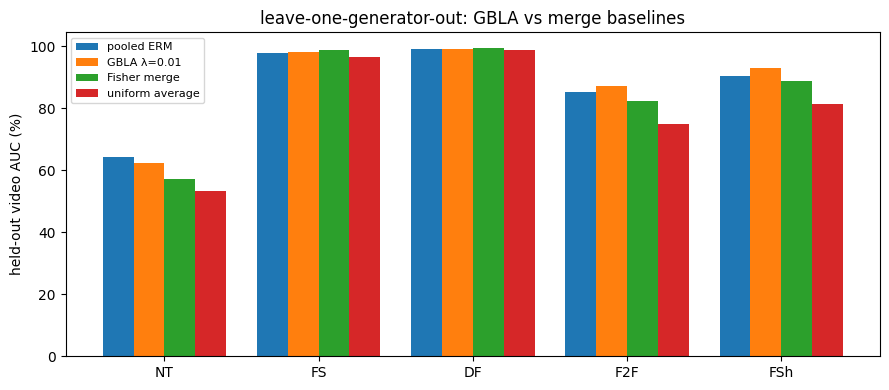

mean held-out: pooled 87.49  GBLA 88.04  Fisher 85.34  uniform 81.06
GBLA − pooled: +0.55   GBLA − Fisher: +2.70   Fisher − pooled: -2.15


In [10]:
# 5. Comparison table
rows = []
for held in FOLDS:
    pooled_h, pooled_s = m5_numbers(held, "inf")
    gbla_h, gbla_s = m5_numbers(held, "0.01")
    m = merge_eval[SHORT[held]]
    rows.append({
        "held out": SHORT[held],
        "pooled": pooled_h,
        "GBLA": gbla_h,
        "Fisher": m["fisher"]["held_out"],
        "uniform": m["uniform"]["held_out"],
        "pooled seen": pooled_s,
        "GBLA seen": gbla_s,
        "Fisher seen": m["fisher"]["seen"],
    })
table = pd.DataFrame(rows).set_index("held out")
table.loc["MEAN"] = table.mean()
display(table.round(2))
(M6_DIR / "logo_baselines.csv").write_text(table.to_csv())

plot = table.drop(index="MEAN")
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(plot))
w = 0.2
ax.bar(x - 1.5 * w, plot["pooled"], width=w, label="pooled ERM")
ax.bar(x - 0.5 * w, plot["GBLA"], width=w, label="GBLA λ=0.01")
ax.bar(x + 0.5 * w, plot["Fisher"], width=w, label="Fisher merge")
ax.bar(x + 1.5 * w, plot["uniform"], width=w, label="uniform average")
ax.set_xticks(x, plot.index)
ax.set_ylabel("held-out video AUC (%)")
ax.set_title("leave-one-generator-out: GBLA vs merge baselines")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

mean = table.loc["MEAN"]
print(f"mean held-out: pooled {mean['pooled']:.2f}  GBLA {mean['GBLA']:.2f}  "
      f"Fisher {mean['Fisher']:.2f}  uniform {mean['uniform']:.2f}")
print(f"GBLA − pooled: {mean['GBLA'] - mean['pooled']:+.2f}   "
      f"GBLA − Fisher: {mean['GBLA'] - mean['Fisher']:+.2f}   "
      f"Fisher − pooled: {mean['Fisher'] - mean['pooled']:+.2f}")